Grafico salvato: C:\Users\RHEODLS\Documents\Luca\script_rheoflu\results\technique_comparison\stress_methods_comparison.png
Dati numerici salvati: C:\Users\RHEODLS\Documents\Luca\script_rheoflu\results\technique_comparison\stress_methods_comparison.csv
Metadati salvati: C:\Users\RHEODLS\Documents\Luca\script_rheoflu\results\technique_comparison\stress_methods_comparison.json


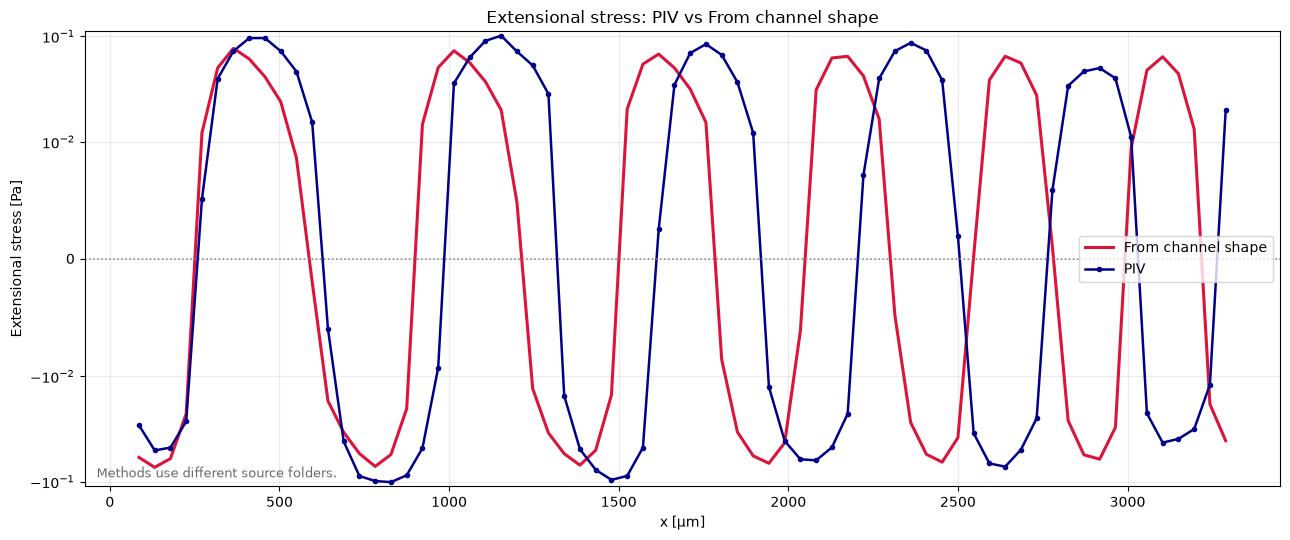

In [34]:
from pathlib import Path
import json
import csv
import matplotlib.pyplot as plt
import numpy as np

# Individua la cartella del progetto anche se il kernel parte da un'altra directory.
project_dir = Path.cwd()
if not (project_dir / "results" / "stress_from_channel").exists():
    project_dir = Path(r"C:\Users\RHEODLS\Documents\Luca\script_rheoflu")

shape_csv = project_dir / "results" / "stress_from_channel" / "stress_profile_space.csv"
piv_csv = project_dir / "results" / "piv" / "extensional_stress_profile.csv"
shape_json = project_dir / "results" / "stress_from_channel" / "extensional_stress_from_channel_shape.json"
piv_json = project_dir / "results" / "piv" / "extensional_stress_profile.json"

def load_plot_component(csv_path, array_key):
    with csv_path.open(encoding="utf-8-sig", newline="") as data_file:
        rows = [row for row in csv.DictReader(data_file) if row["array_key"] == array_key]
    rows.sort(key=lambda row: int(row["index_0"]))
    return np.asarray([float(row["value"]) for row in rows])

x_shape_um = load_plot_component(shape_csv, "axes_1_line_0_x")
stress_shape_pa = load_plot_component(shape_csv, "axes_1_line_0_y")
x_piv_um = load_plot_component(piv_csv, "axes_1_line_0_x")
stress_piv_pa = load_plot_component(piv_csv, "axes_1_line_0_y")
with shape_json.open(encoding="utf-8") as file:
    shape_meta = json.load(file)
with piv_json.open(encoding="utf-8") as file:
    piv_meta = json.load(file)

if len(x_shape_um) != len(stress_shape_pa) or len(x_piv_um) != len(stress_piv_pa):
    raise ValueError("Ogni profilo deve avere coordinate x e stress della stessa lunghezza.")
if shape_meta["x_units"] != piv_meta["x_units"] or shape_meta["stress_units"] != piv_meta["stress_units"]:
    raise ValueError("Le unità dei due profili non coincidono.")

common_x_min = max(np.min(x_shape_um), np.min(x_piv_um))
common_x_max = min(np.max(x_shape_um), np.max(x_piv_um))
common_x_mask = (x_piv_um >= common_x_min) & (x_piv_um <= common_x_max)
x_common_um = x_piv_um[common_x_mask]
if x_common_um.size == 0:
    raise ValueError("I due profili non hanno coordinate x in comune.")

shape_sort_order = np.argsort(x_shape_um)
stress_shape_common_pa = np.interp(
    x_common_um,
    x_shape_um[shape_sort_order],
    stress_shape_pa[shape_sort_order],
)
stress_piv_common_pa = stress_piv_pa[common_x_mask]

shape_source = shape_meta["analysis_parameters"]["channel_image"]
piv_source = piv_meta["analysis_parameters"]["input_dir"]
same_folder = Path(shape_source).parent == Path(piv_source)
source_note = "Both methods use the same source folder." if same_folder else "Methods use different source folders."

output_dir = project_dir / "results" / "technique_comparison"
output_dir.mkdir(parents=True, exist_ok=True)
plot_path = output_dir / "stress_methods_comparison.png"
data_path = plot_path.with_suffix(".csv")
metadata_path = plot_path.with_suffix(".json")

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(x_common_um, stress_shape_common_pa, color="crimson", linewidth=2.2, label="From channel shape")
ax.plot(x_common_um, 0.00007*stress_piv_common_pa, color="darkblue", marker="o", markersize=3, linewidth=1.8, label="PIV")
ax.axhline(0, color="gray", linestyle=":", linewidth=1.1)
ax.set_xlabel(f"x [{shape_meta['x_units']}]")
ax.set_ylabel(f"Extensional stress [{shape_meta['stress_units']}]")
ax.set_title("Extensional stress: PIV vs From channel shape")
ax.set_yscale("symlog", linthresh=0.01)
ax.grid(True, which="both", alpha=0.25)
ax.legend()
ax.text(0.01, 0.02, source_note, transform=ax.transAxes, fontsize=9, color="dimgray")
fig.tight_layout()
fig.savefig(plot_path, dpi=300, bbox_inches="tight")

with data_path.open("w", encoding="utf-8-sig", newline="") as data_file:
    writer = csv.DictWriter(data_file, fieldnames=["method", "x_um", "stress_pa"])
    writer.writeheader()
    for x_value, stress_value in zip(x_common_um, stress_shape_common_pa):
        writer.writerow({"method": "From channel shape", "x_um": x_value, "stress_pa": stress_value})
    for x_value, stress_value in zip(x_common_um, stress_piv_common_pa):
        writer.writerow({"method": "PIV", "x_um": x_value, "stress_pa": stress_value})
comparison_metadata = {
    "plot_type": "stress_method_comparison",
    "title": "Extensional stress: PIV vs From channel shape",
    "x_units": shape_meta["x_units"],
    "stress_units": shape_meta["stress_units"],
    "y_scale": "symlog",
    "symlog_linthresh_pa": 0.01,
    "common_x_range_um": [float(common_x_min), float(common_x_max)],
    "common_x_points": int(len(x_common_um)),
    "shape_interpolation": "linear at PIV x coordinates within the overlapping x range",
    "same_dataset_folder": same_folder,
    "source_data": {
        "from_channel_shape_csv": str(shape_csv),
        "from_channel_shape_metadata": str(shape_json),
        "piv_csv": str(piv_csv),
        "piv_metadata": str(piv_json),
    },
    "numeric_data_file": data_path.name,
    "series": {
        "from_channel_shape": {"x_key": "from_channel_shape_x_um", "y_key": "from_channel_shape_stress_pa", "n_points": int(len(x_common_um))},
        "piv": {"x_key": "piv_x_um", "y_key": "piv_stress_pa", "n_points": int(len(x_common_um))},
    },
}
with metadata_path.open("w", encoding="utf-8") as file:
    json.dump(comparison_metadata, file, indent=2, ensure_ascii=False)

print(f"Grafico salvato: {plot_path.resolve()}")
print(f"Dati numerici salvati: {data_path.resolve()}")
print(f"Metadati salvati: {metadata_path.resolve()}")
plt.show()

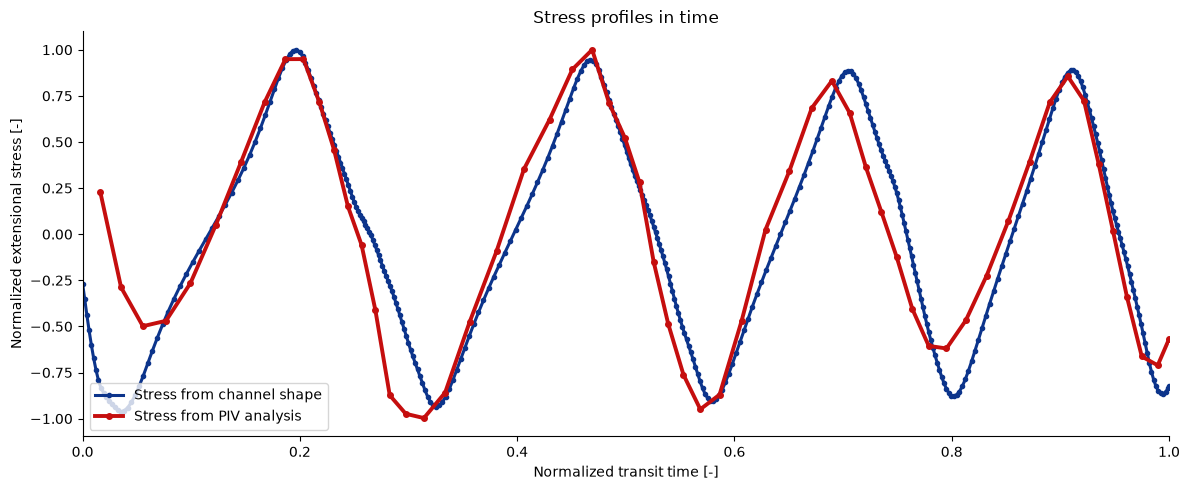

Grafico temporale aggiornato: C:\Users\RHEODLS\Documents\Luca\script_rheoflu\results\technique_comparison\stress_methods_time_comparison.png
Massimi allineati a x=0.1517; traslazione PIV=+0.0076


In [94]:
# Allinea il primo massimo locale dei due profili nel tempo normalizzato.
def first_local_maximum_index(values):
    maxima = np.flatnonzero(
        (values[1:-1] >= values[:-2]) &
        (values[1:-1] > values[2:])
    ) + 1

    if len(maxima) == 0:
        raise ValueError("Non è stato trovato un massimo locale interno.")

    return int(maxima[0])


channel_first_peak_index = first_local_maximum_index(channel_stress_normalized)
piv_first_peak_index = first_local_maximum_index(piv_stress_normalized)

channel_first_peak_time = channel_time_normalized[channel_first_peak_index]
piv_first_peak_time = piv_time_normalized[piv_first_peak_index]
piv_time_shift = channel_first_peak_time - piv_first_peak_time

channel_time_aligned = channel_time_normalized.copy()
piv_time_aligned = piv_time_normalized + piv_time_shift+0.005

comparison_dir = project_dir / "results" / "technique_comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)
time_plot_path = comparison_dir / "stress_methods_time_comparison.png"




def local_maximum_indices(values):
    return np.flatnonzero(
        (values[1:-1] >= values[:-2]) & (values[1:-1] > values[2:])
    ) + 1

channel_peaks = local_maximum_indices(channel_stress_normalized)
piv_peaks = local_maximum_indices(piv_stress_normalized)
if len(channel_peaks) < 3 or len(piv_peaks) < 3:
    raise ValueError("Per tagliare le ultime due oscillazioni servono almeno tre massimi locali per profilo.")

# Cutoff a metà tra la quarta e la quinta cresta, condiviso dai due profili
last_kept_peak = max(
    channel_time_aligned[channel_peaks[-3]],
    piv_time_aligned[piv_peaks[-3]],
)
first_removed_peak = min(
    channel_time_aligned[channel_peaks[-2]],
    piv_time_aligned[piv_peaks[-2]],
)
time_cutoff = (last_kept_peak + first_removed_peak) / 2

def crop_and_rescale(time, stress):
    keep = time < time_cutoff
    cropped_time = np.append(time[keep], time_cutoff) / time_cutoff
    cropped_stress = np.append(
        stress[keep], np.interp(time_cutoff, time, stress)
    )
    return cropped_time, cropped_stress

channel_time_plot, channel_stress_plot = crop_and_rescale(
    channel_time_aligned, channel_stress_normalized
)
piv_time_plot, piv_stress_plot = crop_and_rescale(
    piv_time_aligned, piv_stress_normalized
)





fig, ax = plt.subplots(figsize=(12,5))

ax.plot(
    channel_time_plot,
    channel_stress_plot,
    color="#0C348B",
    marker="o",
    markersize=3,
    linewidth=2.2,
    #linestyle=":",
    label="Stress from channel shape",
)
ax.plot(
    piv_time_plot,
    piv_stress_plot,
    color="#c50e0e",
    marker="o",
    markersize=4,
    linewidth=2.8,
    linestyle="-",
    label="Stress from PIV analysis",
)


ax.set_xlim(0, 1)
ax.set_xlim(0, 1)
ax.set_xlabel("Normalized transit time [-]")
ax.set_ylabel("Normalized extensional stress [-]")
ax.set_title("Stress profiles in time")
ax.legend(loc="lower left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(time_plot_path, dpi=300, bbox_inches="tight", transparent=True)
plt.show()

print(f"Grafico temporale aggiornato: {time_plot_path.resolve()}")
print(f"Massimi allineati a x={channel_first_peak_time:.4f}; traslazione PIV={piv_time_shift:+.4f}")

In [36]:

with time_data_path.open("w", encoding="utf-8-sig", newline="") as data_file:
    writer = csv.DictWriter(data_file, fieldnames=["method", "time_normalized", "stress_normalized"])
    writer.writeheader()
    for time_value, stress_value in zip(channel_time_plot, channel_stress_plot):
        writer.writerow({"method": "Stress from channel shape", "time_normalized": time_value, "stress_normalized": stress_value})
    for time_value, stress_value in zip(piv_time_plot, piv_stress_plot):
        writer.writerow({"method": "Stress from PIV analysis", "time_normalized": time_value, "stress_normalized": stress_value})

time_metadata = {
    "plot_type": "stress_method_time_comparison",
    "title": "Normalized stress profiles in time (last oscillations cropped)",
    "time_units": "dimensionless",
    "time_normalization": "each profile scaled independently; time axis is cropped at the shared cutoff and rescaled to 0-1",
    "time_cutoff_aligned": float(time_cutoff),
    "original_time_durations_ms": {
        "from_channel_shape": float(channel_time_duration_ms),
        "piv": float(piv_time_duration_ms),
    },
    "stress_units": "dimensionless",
    "stress_normalization": "each profile divided by its maximum absolute stress",
    "normalization_scales_pa": {
        "from_channel_shape": float(channel_stress_scale),
        "piv": float(piv_stress_scale),
    },
    "y_scale": "linear",
    "channel_time_mapping": shape_time_meta.get("time_mapping"),
    "piv_time_mapping": "trapezoidal integration of dt = dx / u(x), with x in um and u in um/s",
    "source_data": {
        "from_channel_shape_csv": str(shape_time_csv),
        "from_channel_shape_metadata": str(shape_time_json),
        "piv_space_csv": str(piv_space_csv),
        "piv_space_metadata": str(piv_space_json),
    },
    "numeric_data_file": time_data_path.name,
    "numeric_data_columns": ["method", "time_normalized", "stress_normalized"],
    "series": {
        "from_channel_shape": {"n_points": int(len(channel_time_plot))},
        "piv": {"n_points": int(len(piv_time_plot))},
    },
}
with time_metadata_path.open("w", encoding="utf-8") as file:
    json.dump(time_metadata, file, indent=2, ensure_ascii=False)

print(f"Grafico temporale salvato: {time_plot_path.resolve()}")
print(f"Dati temporali salvati: {time_data_path.resolve()}")
print(f"Metadati salvati: {time_metadata_path.resolve()}")
print(f"Durata originale canale: {channel_time_duration_ms:.3f} ms; tempo normalizzato: {channel_time_normalized[0]:.1f}-{channel_time_normalized[-1]:.1f}")
print(f"Durata originale PIV: {piv_time_duration_ms:.3f} ms; tempo normalizzato: {piv_time_normalized[0]:.1f}-{piv_time_normalized[-1]:.1f}")

Grafico temporale salvato: C:\Users\RHEODLS\Documents\Luca\script_rheoflu\results\technique_comparison\stress_methods_time_comparison.png
Dati temporali salvati: C:\Users\RHEODLS\Documents\Luca\script_rheoflu\results\technique_comparison\stress_methods_time_comparison.csv
Metadati salvati: C:\Users\RHEODLS\Documents\Luca\script_rheoflu\results\technique_comparison\stress_methods_time_comparison.json
Durata originale canale: 275.126 ms; tempo normalizzato: 0.0-1.0
Durata originale PIV: 75527.412 ms; tempo normalizzato: 0.0-1.0
